In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# Correlation discovery
Which indicators move together across the EU27 + GBR/USA/JPN, and where does Italy sit relative to those relationships?
**Associations only, never causal.** About 30 countries and ~15,000 indicator pairs means a naive screen is mostly noise,
so every screen below is followed by Benjamini-Hochberg false-discovery control and robustness stamps
(leave-one-country-out, without Ireland, Spearman vs Pearson). Size-scaled series (counts, EUR millions) and near-duplicates
(|rho| >= 0.95 between differently named series) are dropped. Code: `src/cifresignificative/studies/italy_productivity/analysis/corr.py`, `experiments.py`.

In [2]:
from cifresignificative.studies.italy_productivity.analysis import corr, experiments as ex
M_ = corr.panel_matrix(panel)
res = ex.run_all(panel)
funnel = pd.DataFrame({"survivors (FDR 5%, not duplicate)": {k: len(v) for k, v in res.items() if k.startswith(("e1", "e2", "e3"))},
                       "robust": {k: int(v["robust"].sum()) if "robust" in v else np.nan for k, v in res.items() if k.startswith(("e1", "e2", "e3"))}})
display(funnel)

,"survivors (FDR 5%, not duplicate)",robust
e1_levels,260,260.0
e1_levels_raw,997,992.0
e2_changes,429,427.0
e3_within,1127,NaN
e3_regimes,1127,NaN
e1_split_sample,373,NaN
e1_split_sample_raw,1988,NaN


## Why we control for income
Rich countries are better on almost everything, so a raw cross-section mostly rediscovers one 'development' factor. `e1_levels` correlates what is left after removing the log-GDP-per-head fit; `e1_levels_raw` does not.

In [3]:
top = res["e1_levels"].head(15)[["x", "y", "n", "rho", "q_value", "robust"]]
display(top.round(3))
# null check: shuffling each indicator across countries should leave ~0 discoveries
X1 = corr.cross_section(M_, "level", (2015, 2019))
print("discoveries on shuffled data:", corr.permutation_null(X1, n_perm=3))

,x,y,n,rho,q_value,robust
0,gov_debt_pct_gdp,gov_interest_pct_gdp,27,0.934,0.0,True
1,gov_interest_pct_gdp,imf_gov_debt_pct_gdp,27,0.934,0.0,True
2,bachelor_grads_30plus_pct,mean_age_grads_bachelor,27,0.933,0.0,True
3,arope_linked,arope_old,27,0.916,0.0,True
4,wb_pisa_math,wb_pisa_science,27,0.912,0.0,True
5,employment_rate_20_64_male,recent_secondary_grads_employment_rate,27,0.890,0.0,True
6,life_expectancy_birth,preventable_mortality_rate,27,-0.885,0.0,True
7,imf_unemployment_rate,youth_unemployment_rate,27,0.885,0.0,True
8,unemployment_rate,youth_unemployment_rate,27,0.883,0.0,True
9,preventable_mortality_rate,treatable_mortality_rate,27,0.883,0.0,True


discoveries on shuffled data: [0, 0, 0]


## E2 - do improvements co-occur? (change 2005-09 to 2015-19)

In [4]:
display(res["e2_changes"].head(15)[["x", "y", "n", "rho", "q_value", "robust"]].round(3))

,x,y,n,rho,q_value,robust
0,unemployment_rate,youth_unemployment_rate,28,0.943,0.0,True
1,wb_unemployment_ilo,youth_unemployment_rate,28,0.935,0.0,True
2,recent_secondary_grads_employment_rate,youth_unemployment_rate,28,-0.920,0.0,True
3,employment_rate_20_64,youth_unemployment_rate,28,-0.914,0.0,True
4,employment_rate_20_64_male,wb_unemployment_ilo,28,-0.908,0.0,True
5,employment_rate_20_64_male,youth_unemployment_rate,28,-0.897,0.0,True
6,employment_rate_20_64,unemployment_rate,28,-0.893,0.0,True
7,employment_rate_20_64,wb_unemployment_ilo,28,-0.886,0.0,True
8,employment_rate_20_64_male,unemployment_rate,28,-0.885,0.0,True
9,ameco_tfp_index,wb_gdp_pc_ppp_const,30,0.880,0.0,True


## E3 - within-country co-movement (year-on-year changes, demeaned by country)

In [5]:
display(res["e3_within"].head(15)[["x", "y", "n", "rho", "q_value"]].round(3))

,x,y,n,rho,q_value
0,emigration_nationals_25_34_per_1000,net_migration_nationals_25_34_per_1000,238,-0.944,0.0
1,stem_share_students_pct,women_share_students_pct,309,-0.909,0.0
2,students_per_100_pop_20_24,women_share_students_pct,316,0.904,0.0
3,life_expectancy_birth,preventable_mortality_rate,261,-0.895,0.0
4,emigration_nationals_per_1000,net_migration_nationals_per_1000,480,-0.890,0.0
5,employment_rate_20_64_male,unemployment_rate,401,-0.886,0.0
6,immigration_per_1000,net_migration_registered_per_1000,507,0.882,0.0
7,emigration_nationals_per_1000,net_migration_nationals_25_34_per_1000,238,-0.877,0.0
8,emigration_nationals_25_34_per_1000,net_migration_nationals_per_1000,241,-0.873,0.0
9,employment_rate_20_64,unemployment_rate,401,-0.873,0.0


## E5 - what moves with Italy's gap?
Spearman correlation of year-on-year changes in the gap (Italy minus median of the other EU27) for each indicator against the gap in the target.

In [6]:
for t in ("e5_italy_gap_gdp", "e5_italy_gap_employment"):
    print(t); display(res[t].head(8).round(3))

e5_italy_gap_gdp


,target,indicator,n,rho,p,q_value,significant
0,gdp_real_pc,imf_gov_debt_pct_gdp,20,-0.705,0.001,0.042,True
1,gdp_real_pc,gov_debt_pct_gdp,20,-0.691,0.001,0.042,True
2,gdp_real_pc,pension_spend_pct_gdp,19,-0.681,0.001,0.049,True
3,gdp_real_pc,asylum_first_applicants_nr,14,0.638,0.014,0.186,False
4,gdp_real_pc,emigration_nationals_per_1000,16,-0.596,0.015,0.186,False
5,gdp_real_pc,tax_wedge_low_wage,20,-0.584,0.007,0.159,False
6,gdp_real_pc,ameco_output_gap_pct_potential,20,0.577,0.008,0.159,False
7,gdp_real_pc,gdp_nominal_meur,20,0.572,0.008,0.159,False


e5_italy_gap_employment


,target,indicator,n,rho,p,q_value,significant
0,employment_rate_20_64,current_account_pct_gdp,20,-0.618,0.004,0.226,False
1,employment_rate_20_64,healthy_life_years_birth,18,0.606,0.008,0.226,False
2,employment_rate_20_64,gov_debt_pct_gdp,20,-0.573,0.008,0.226,False
3,employment_rate_20_64,wgi_government_effectiveness,20,0.573,0.008,0.226,False
4,employment_rate_20_64,imf_current_account_pct_gdp,20,-0.555,0.011,0.235,False
5,employment_rate_20_64,wb_gdp_pc_ppp_const,20,0.540,0.014,0.235,False
6,employment_rate_20_64,imf_gov_debt_pct_gdp,20,-0.529,0.016,0.235,False
7,employment_rate_20_64,gfcf_pct_gdp,20,0.526,0.017,0.235,False


## E7 - literature hypotheses with panel fixed effects
Entity + year FE, entity-clustered SEs, also without Ireland. `italy_resid_z` = Italy's distance from the cross-country line fitted on the other countries (2015-19), in residual SDs.

In [7]:
h = res["e7_hypotheses"]
display(h[["id", "label", "expected_sign", "coef", "p", "q_value", "sign_agrees", "p_ex_irl", "italy_resid_z", "n_obs"]].round(3))

,id,label,expected_sign,coef,p,q_value,sign_agrees,p_ex_irl,italy_resid_z,n_obs
0,H1,Higher TFP goes with higher GDP per head,1,488.845,0.009,0.016,True,0.000,-0.051,535
1,H2,Higher long-term yields go with lower investment,-1,-0.496,0.000,0.000,True,0.000,-0.774,531
2,H3,Faster growth goes with lower debt/GDP,-1,-0.599,0.000,0.001,True,0.002,1.565,547
3,H4,Bigger deficits go with lower public investment,1,-0.060,0.000,0.001,False,0.000,-1.280,563
4,H5,Pension spending crowds out education spending,-1,0.140,0.013,0.019,False,0.013,-1.265,512
5,H6,Pension burden goes with more NEET youth,1,0.925,0.000,0.000,True,0.000,2.597,416
6,H7,Higher pension spending goes with lower old-ag...,-1,-1.496,0.003,0.006,True,0.000,0.040,421
7,H8,Graduate-heavy cohorts emigrate more,1,0.265,0.164,0.213,True,0.125,-0.333,222
8,H9,Female employment goes with GDP per head,1,319.642,0.000,0.000,True,0.000,0.625,444
9,H10,Full-time childcare goes with female employment,1,0.161,0.198,0.234,True,0.183,-2.340,456


### Robustness of E7: the GDP denominator (exploratory, added on 2026-11-11 after the results above were seen)
Several variables are ratios to GDP: in a bad year a country's GDP falls and all its ratios rise, while youth inactivity rises and employment falls, so two series can move together through the country's own cycle (year effects remove only the cycle common to all members). Two checks, neither part of the pre-specified test: (1) the same regression with log real GDP per head held fixed (`gdp_control`; not applicable when GDP per head is the outcome, and it can also remove a real link when GDP is part of the mechanism); (2) for the three pension hypotheses, pension spending per person aged 65+ in real euro (national HICP) instead of % of GDP, for all members and for the euro-area members (outside the euro the euro amount moves with the exchange rate).

In [8]:
display(h[["id", "label", "coef", "p", "q_value", "coef_gdp_control", "p_gdp_control", "gdp_control"]].round(3))
print("significant before:", int((h.q_value <= 0.05).sum()), "|", h[h.q_value <= 0.05].gdp_control.value_counts().to_dict())
display(res["e7_pension_real"].round(3))

,id,label,coef,p,q_value,coef_gdp_control,p_gdp_control,gdp_control
0,H1,Higher TFP goes with higher GDP per head,488.845,0.009,0.016,NaN,NaN,not applicable (the outcome is GDP per head)
1,H2,Higher long-term yields go with lower investment,-0.496,0.000,0.000,-0.447,0.001,holds
2,H3,Faster growth goes with lower debt/GDP,-0.599,0.000,0.001,-0.291,0.201,not distinguishable from the cycle
3,H4,Bigger deficits go with lower public investment,-0.060,0.000,0.001,-0.063,0.000,holds
4,H5,Pension spending crowds out education spending,0.140,0.013,0.019,0.086,0.052,not distinguishable from the cycle
5,H6,Pension burden goes with more NEET youth,0.925,0.000,0.000,0.411,0.122,not distinguishable from the cycle
6,H7,Higher pension spending goes with lower old-ag...,-1.496,0.003,0.006,-0.868,0.150,not distinguishable from the cycle
7,H8,Graduate-heavy cohorts emigrate more,0.265,0.164,0.213,0.267,0.298,not significant before
8,H9,Female employment goes with GDP per head,319.642,0.000,0.000,NaN,NaN,not applicable (the outcome is GDP per head)
9,H10,Full-time childcare goes with female employment,0.161,0.198,0.234,0.176,0.102,not significant before


significant before: 9 | {'not distinguishable from the cycle': 4, 'holds': 3, 'not applicable (the outcome is GDP per head)': 2}


,id,y,sample,spec,coef,p,n_obs,n_countries
0,H5,edu_spend_pct_gdp,all members,pension % of GDP,0.140,0.013,512,26
1,H5,edu_spend_pct_gdp,all members,real per person 65+,0.717,0.036,493,26
2,H5,edu_spend_pct_gdp,all members,"real per person 65+, GDP control",1.305,0.000,488,26
3,H5,edu_spend_pct_gdp,euro area,pension % of GDP,0.129,0.031,372,19
4,H5,edu_spend_pct_gdp,euro area,real per person 65+,0.524,0.361,356,19
5,H5,edu_spend_pct_gdp,euro area,"real per person 65+, GDP control",1.197,0.000,353,19
6,H6,neet_rate_15_29,all members,pension % of GDP,0.925,0.000,416,26
7,H6,neet_rate_15_29,all members,real per person 65+,-0.961,0.678,403,26
8,H6,neet_rate_15_29,all members,"real per person 65+, GDP control",2.269,0.280,398,26
9,H6,neet_rate_15_29,euro area,pension % of GDP,0.958,0.000,309,19


## E4 - lead-lag
For each hypothesis: does x(t-k) predict y(t) (entity + year FE), and does y(t-k) predict x(t)? Verdict 'x leads' / 'y leads' when only one direction is significant at 5%. Predictive order only.

In [9]:
ll = res["e4_lead_lag"]
display(ll.pivot_table(index=["id", "x", "y"], columns="lag", values="verdict", aggfunc="first"))

,,lag,1,2,3
id,x,y,,,
H1,ameco_tfp_index,gdp_real_pc,both,both,both
H10,childcare_under3_30h_plus_pct,employment_rate_20_64_female,y leads,y leads,y leads
H11,ameco_tfp_index,net_earnings_pps,neither,neither,neither
H12,wgi_government_effectiveness,gdp_real_pc,y leads,y leads,neither
H13,early_leavers_18_24,neet_rate_15_29,both,x leads,x leads
H2,long_term_yield,gfcf_pct_gdp,x leads,x leads,x leads
H3,gdp_growth,gov_debt_pct_gdp,x leads,both,both
H4,gov_balance_pct_gdp,gov_pubinv_pct_gdp,y leads,y leads,y leads
H5,pension_spend_pct_gdp,edu_spend_pct_gdp,y leads,y leads,y leads


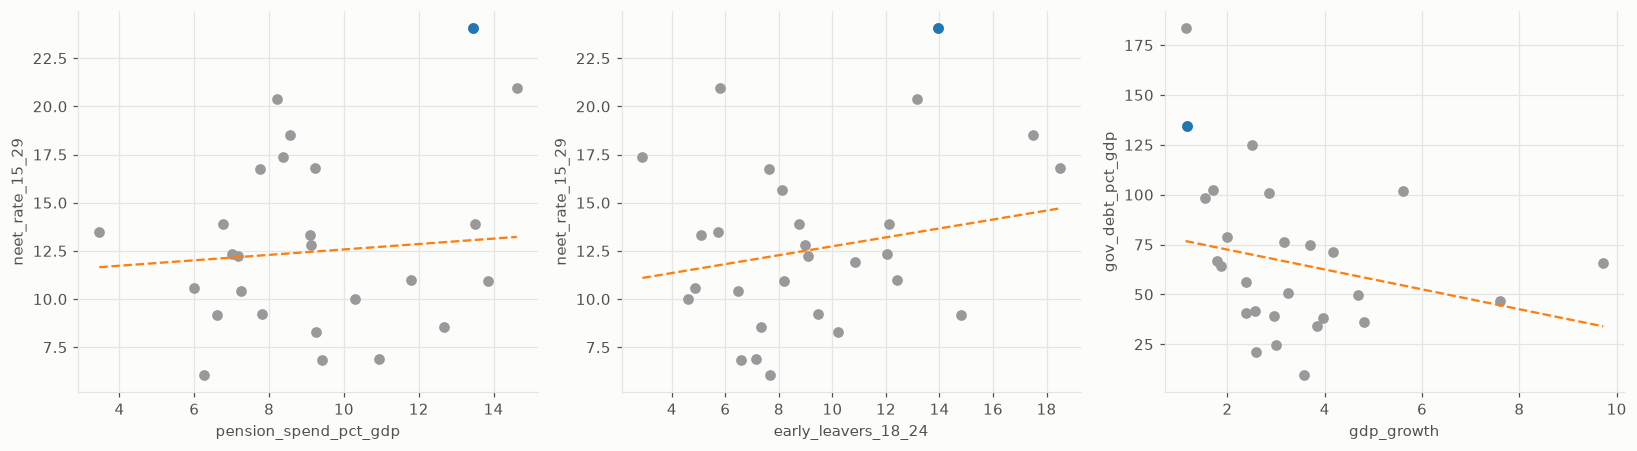

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (x, y) in zip(axes, [("pension_spend_pct_gdp", "neet_rate_15_29"), ("early_leavers_18_24", "neet_rate_15_29"), ("gdp_growth", "gov_debt_pct_gdp")]):
    d = X1[[x, y]].dropna()
    ax.scatter(d[x], d[y], color="0.6")
    ax.scatter(d.loc[["ITA"], x], d.loc["ITA", y], color="C0", zorder=3)
    b, a = np.polyfit(d.drop("ITA")[x], d.drop("ITA")[y], 1)
    xs = np.linspace(d[x].min(), d[x].max(), 20); ax.plot(xs, a + b * xs, "--", color="C1")
    ax.set_xlabel(x); ax.set_ylabel(y)
plt.tight_layout(); plt.show()

## Takeaways (Eurostat, World Bank, IMF, AMECO, OECD; descriptive associations only)
- **Income drives most of the raw signal.** The 2015-19 cross-section yields about 1,000 FDR-significant pairs; after removing the log-GDP-per-head fit about 260 remain (206 before Eurostat's release of 5 November 2026, which revised GDP per head for five members: the count is sensitive to the income control). Shuffling indicators across countries gives 0 discoveries, so the screen is not producing noise on its own.
- **The leaders are mostly definitional or same-family pairs** (life expectancy vs preventable mortality, PISA maths vs science, unemployment vs youth unemployment). Name-based filters catch the obvious ones; the list still needs human curation before any pair is read as a finding. Robustness checks barely discriminate among FDR survivors (nearly all pass), so they flag fragile pairs rather than rank good ones.
- **Italy's gap in GDP per head moves with its gaps in debt and pensions.** Year-on-year changes in the gap correlate at -0.71 with government debt/GDP, -0.71 with the IMF debt series (the same quantity, so not independent) and -0.68 with pension spending (q = 0.03 to 0.05, n = 19-20 years). No indicator passes FDR for the employment-rate gap (best: current account, rho = -0.62, q = 0.19).
- **Literature hypotheses (panel FE, entity + year effects):** 9 of 13 are significant at q < 0.05, and 7 of those go the expected way (TFP-GDP, yields-investment, growth-debt, pensions-55-64 employment, pensions-NEET, female employment-GDP, early leaving-NEET). Two significant results go the *opposite* way to the stated expectation (H4 public investment vs balance, H5 pensions vs education spending) and should be treated as refuted or mis-specified, not as support. Four show no significant association (graduates-emigration, childcare-female employment, TFP-net earnings, government effectiveness-GDP; q > 0.2).
- **Three of the seven are not distinguishable from the GDP denominator (exploratory checks, after the results were seen).** With log real GDP per head held fixed, yields-investment and early leaving-NEET hold (p 0.001 both); growth-debt, pensions-NEET and pensions-55-64 employment do not (p 0.201, 0.122, 0.150); TFP-GDP and female employment-GDP cannot be checked this way (GDP per head is the outcome). The two opposite-sign results: public investment vs balance holds (p < 0.001), pensions vs education is borderline (p 0.052). Measured as real euro per person aged 65+ instead of % of GDP, pension spending has no association with NEET (coefficient -0.96, p 0.678; euro area p 0.889) or with 55-64 employment (-0.52, p 0.929; euro area p 0.843): those two results came from the denominator. Pensions vs education stays positive with the real measure for all members (p 0.036), not in the euro area alone (p 0.361). The pre-specified result above stands as it was run; these columns say how to read it.
- **Italy against the cross-country line (2015-19):** NEET is 2.6 residual SDs above the line implied by pension spending and 2.6 above the one implied by early school leaving; female employment is 2.3 SDs below the line implied by full-time childcare coverage.
- **Lead-lag (predictive order, 1-3 years):** female employment predicts GDP per head at every lag but not the reverse (H9); long-term yields predict investment (H2); early school leaving predicts NEET at 2-3 years (H13); pension spending predicts 55-64 employment at 2-3 years (H7). The reverse direction dominates for childcare vs female employment (H10), budget balance vs public investment (H4) and pension vs education spending (H5), so the stated direction of those hypotheses is not supported. TFP-GDP (H1) is significant both ways, and TFP-earnings, government effectiveness-GDP and graduates-emigration show nothing either way.
- **Limits:** ~30 countries and 15-20 years; provisional and broken observations are dropped; same-quantity pairs under different names can survive; no causal identification, and lead-lag tests only show predictive order.